# EDA of the tiny dataset

**Group E01** — Project 01, Artificial Intelligence 2026-27. Supporting notebook of the main one.

In [1]:
import sys, os
sys.path.append(os.path.abspath(".."))   # so Python finds the 'src' folder

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.model import Problem, State, Stop
from src import informed, local_search, csp

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

prob = Problem.from_csv("../data_tiny")          # development dataset
prob_small = Problem.from_csv("../data_small")   # larger dataset, used to check that the code scales

# 2. Exploratory Data Analysis (EDA)

We load the `tiny` dataset (development) and validate it before using it. The `small` dataset has the same structure.

In [2]:
from pathlib import Path

tables = {f.stem: pd.read_csv(f) for f in sorted(Path("../data_tiny").glob("*.csv"))}
summary = pd.DataFrame({"rows": {n: len(t) for n, t in tables.items()},
                        "columns": {n: len(t.columns) for n, t in tables.items()}})
summary

,rows,columns
collection_centers,1,5
customers,12,5
delivery_locations,5,5
distance_matrix,72,6
localities,49,6
locations,9,7
order_items,40,9
orders,12,5
producers,3,6
products,15,6


In [3]:
# Rules of the planning horizon, service and handling times (authoritative source)
tables["rules"]

,rule,value,description
0,start_date,2026-10-30,first day of the planning horizon
1,horizon_days,2,number of days
2,flow,producer>warehouse>delivery_location,every product goes through the warehouse
3,stop_service_min,10,service time at each pickup / delivery stop
4,warehouse_handling_min,15,time to unload (and to load) a vehicle at the ...
5,max_warehouse_dwell_h,24,max time a product stays in the warehouse (arr...
6,window_semantics,service_start,windows constrain when the service STARTS
7,avg_speed_kmh,45.0,used to build duration_min
8,route_factor,1.3,used to build distance_km
9,generator_seed,1,seed that produced this dataset


### 2.1 Locations and map

location_type
delivery_location    5
producer             3
collection_center    1


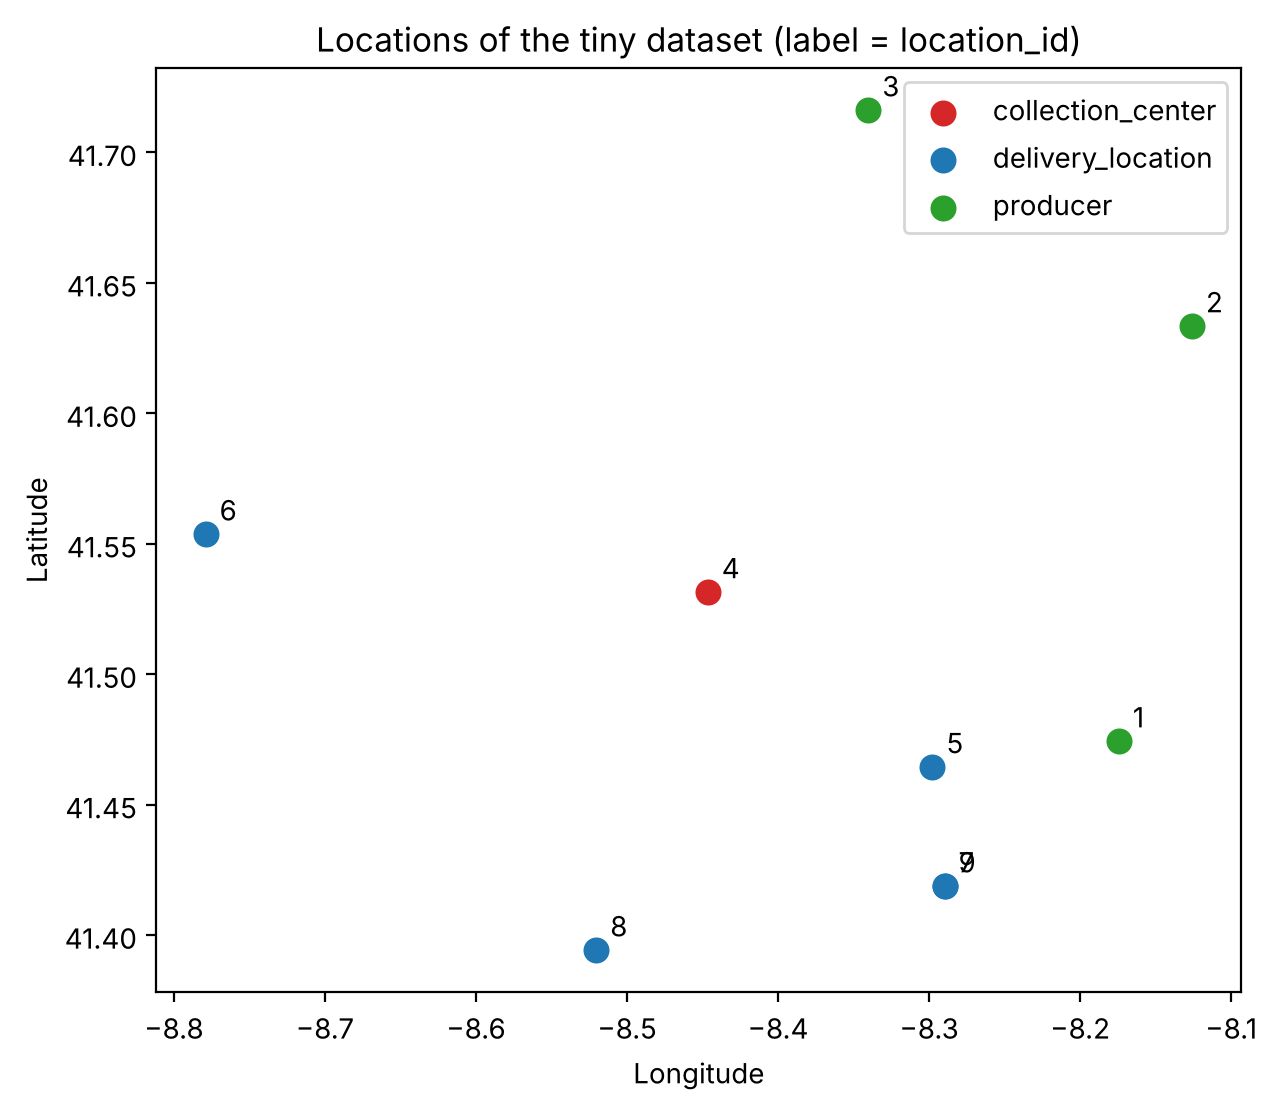

In [4]:
loc = tables["locations"]
print(loc.location_type.value_counts().to_string())

colors = {"producer": "tab:green", "collection_center": "tab:red", "delivery_location": "tab:blue"}
plt.figure(figsize=(7, 6))
for kind, group in loc.groupby("location_type"):
    plt.scatter(group.longitude, group.latitude, label=kind, color=colors.get(kind, "gray"), s=70)
    for _, r in group.iterrows():
        plt.annotate(str(r.location_id), (r.longitude, r.latitude), textcoords="offset points", xytext=(5, 5))
plt.title("Locations of the tiny dataset (label = location_id)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.show()

### 2.2 Integrity checks

In [5]:
# Each check prints OK or raises an error, so a corrupt file cannot go unnoticed.
def check(name, condition):
    assert condition, "FAILED: " + name
    print("OK  ", name)

dist = tables["distance_matrix"]
n = len(loc)
check("location_id is unique", loc.location_id.is_unique)
check("distance matrix has every ordered pair (n*(n-1) rows)", len(dist) == n * (n - 1))
check("no self distances", (dist.origin_location_id != dist.destination_location_id).all())
check("no negative distances or durations", (dist.distance_km >= 0).all() and (dist.duration_min >= 0).all())

# A zero distance is only valid when both locations have the same coordinates
coords = loc.set_index("location_id")[["latitude", "longitude"]]
zero = dist[dist.distance_km == 0]
same_place = [(coords.loc[a] == coords.loc[b]).all() for a, b in zip(zero.origin_location_id, zero.destination_location_id)]
check("zero distances only between locations with identical coordinates (%d pairs)" % len(zero), all(same_place))

items, orders = tables["order_items"], tables["orders"]
check("every item belongs to an existing order", items.order_id.isin(orders.order_id).all())
check("every item has an existing product", items.product_id.isin(tables["products"].product_id).all())
check("every order goes to an existing delivery location", orders.delivery_location_id.isin(tables["delivery_locations"].delivery_location_id).all())
check("pickup windows are valid (end > start)", (pd.to_datetime(items.availability_end) > pd.to_datetime(items.availability_start)).all())
check("delivery windows are valid (end > start)", (pd.to_datetime(items.delivery_end) > pd.to_datetime(items.delivery_start)).all())

# Speed implied by the matrix, to compare it with the vehicle speed
speed = (dist.distance_km / (dist.duration_min / 60)).dropna()
print(f"\nImplied speed in the matrix: min {speed.min():.1f}, max {speed.max():.1f} km/h | vehicle speed: {tables['vehicles'].avg_speed_kmh.tolist()} km/h")

OK   location_id is unique
OK   distance matrix has every ordered pair (n*(n-1) rows)
OK   no self distances
OK   no negative distances or durations
OK   zero distances only between locations with identical coordinates (2 pairs)
OK   every item belongs to an existing order
OK   every item has an existing product
OK   every order goes to an existing delivery location
OK   pickup windows are valid (end > start)
OK   delivery windows are valid (end > start)

Implied speed in the matrix: min 44.9, max 45.1 km/h | vehicle speed: [45.0, 45.0] km/h


### 2.3 Demand versus capacity

In [6]:
rows = []
for o in sorted(prob.order_items):
    rows.append({"order_id": o, "items": len(prob.order_items[o]), "weight_kg": round(prob.order_weight(o), 1),
                 "pickup_day": prob.order_pickup_day(o), "delivery_day": prob.order_delivery_day(o)})
order_table = pd.DataFrame(rows)
display(order_table)

print("Vehicles:", [(v.vehicle_id, v.capacity_kg, "refrigerated" if v.refrigerated else "normal") for v in prob.vehicles])
print("Total weight of all orders: %.1f kg" % order_table.weight_kg.sum())
print("Heaviest order: %.1f kg" % order_table.weight_kg.max())

,order_id,items,weight_kg,pickup_day,delivery_day
0,1,4,22.0,2026-10-31,2026-10-31
1,2,2,6.8,2026-10-30,2026-10-31
2,3,4,21.6,2026-10-31,2026-10-31
3,4,3,26.3,2026-10-30,2026-10-30
4,5,2,9.3,2026-10-31,2026-10-31
5,6,2,16.7,2026-10-31,2026-10-31
6,7,4,33.5,2026-10-31,2026-10-31
7,8,3,18.8,2026-10-30,2026-10-31
8,9,5,36.7,2026-10-30,2026-10-31
9,10,2,9.2,2026-10-30,2026-10-30


Vehicles: [(1, 150.0, 'refrigerated'), (2, 200.0, 'normal')]
Total weight of all orders: 270.0 kg
Heaviest order: 51.1 kg


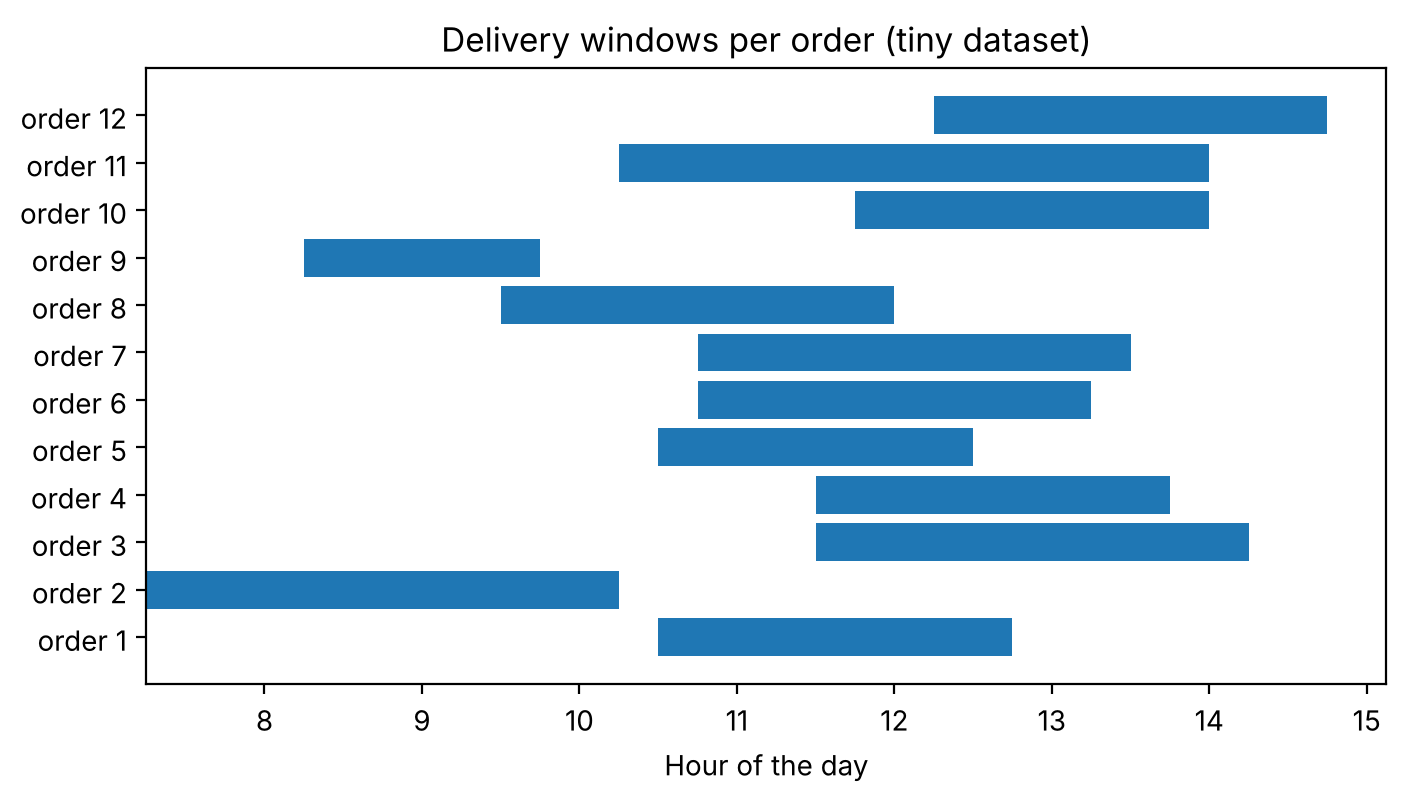

In [7]:
# Delivery window of every order (intersection of its items' windows)
plt.figure(figsize=(8, 4))
for k, o in enumerate(sorted(prob.order_items)):
    start, end = prob.delivery_window(prob.order_items[o])
    plt.barh(k, (end - start) / 60, left=start / 60 % 24, color="tab:blue")
plt.yticks(range(len(prob.order_items)), ["order %d" % o for o in sorted(prob.order_items)])
plt.xlabel("Hour of the day")
plt.title("Delivery windows per order (tiny dataset)")
plt.show()